In [1]:
import os
# This line for the Windows
os.add_dll_directory(r"C:\Users\PC\Desktop\Abrek\openslide-win64-20230414\openslide-win64-20230414\bin")
import datastructure.dataset as dataset
import arguments.setting as setting

In [2]:
# Edit here
data_directories = ["../well_annotated"]
working_directory = "../workdirwell/"
csv_file = "../patients.csv"
qupath_project_file = "../qupath_project/project.qpproj"
fold = 0
# Edit Ends
s = setting.Setting(data_directories, csv_file, working_directory, qupath_project_file)
data = dataset.Dataset(s)
data.set_fold(fold)

Initial 1560 patients
 B529-23 doesn't have a valid wsi(check bugi names)
 B420-21 doesn't have a valid wsi(check bugi names)
 B1867-21 doesn't have a valid wsi(check bugi names)
 B1388-22 doesn't have a valid wsi(check bugi names)
 B340-19 doesn't have a valid wsi(check bugi names)
 B637-23 doesn't have a valid wsi(check bugi names)
 B1000-13 doesn't have a valid wsi(check bugi names)
 B64-23 doesn't have a valid wsi(check bugi names)
 B259-19 doesn't have a valid wsi(check bugi names)
 B249-19 doesn't have a valid wsi(check bugi names)
 B174-21 doesn't have a valid wsi(check bugi names)
 B126-17 doesn't have a valid wsi(check bugi names)
 B47-17 doesn't have a valid wsi(check bugi names)
 B10-20 doesn't have a valid wsi(check bugi names)
 B1666-18 doesn't have a valid wsi(check bugi names)
 B1452-21 doesn't have a valid wsi(check bugi names)
 B1166-19 doesn't have a valid wsi(check bugi names)
 B1009-21 doesn't have a valid wsi(check bugi names)
 B287-17 doesn't have a valid wsi(chec

In [3]:
# Edit Here
model_path = r"C:\Users\PC\Desktop\Fiverr\Max_Pathology\workdirwell\Runs\Pathology-23-10-29-13-57-26\fold_0\model_last"

In [4]:
from models import unet

import torch

network_settings = s.get_network_setting()
data_settings = s.get_data_setting()
targets = network_settings.get_targets()
annotation_threshold = network_settings.get_annotation_threshold()
use_background = int(annotation_threshold != 1.0)
qupath_project = data_settings.get_qupath_project()
all_classes = [i.name for i in qupath_project.path_classes][:-1]
full_background_ratio = data_settings.get_max_full_background_ratio()

if not use_background:
    # There is no background class
    classes = [all_classes[i - 1] for i in targets]
else:
    # There is a background class
    classes = [all_classes[i - 1] for i in targets[1:]]
targets = network_settings.get_targets()
n_classes = 2

model = unet.UNet(network_settings.get_in_channels(),
                n_classes,
                network_settings.get_depth(),
                network_settings.get_wf(),
                True,
                network_settings.get_batch_norm(),
                network_settings.get_up_mode())

model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

In [5]:
from datastructure import dataset_torch

test_set = dataset_torch.PathologyDataset(data.get_test_set(), 
                                          patch_size = data_settings.get_patch_size(),
                                          targets = targets, 
                                          annotation_threshold = annotation_threshold,
                                          max_full_background_ratio = full_background_ratio)

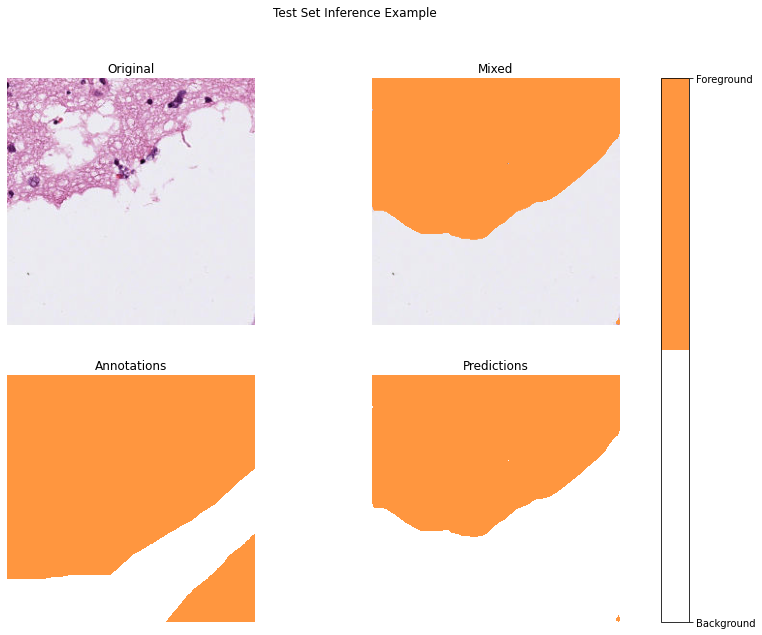

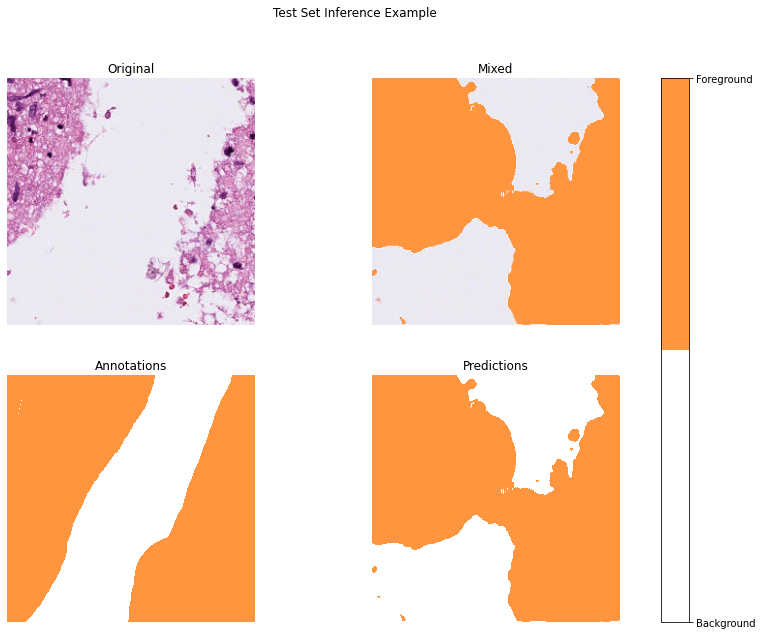

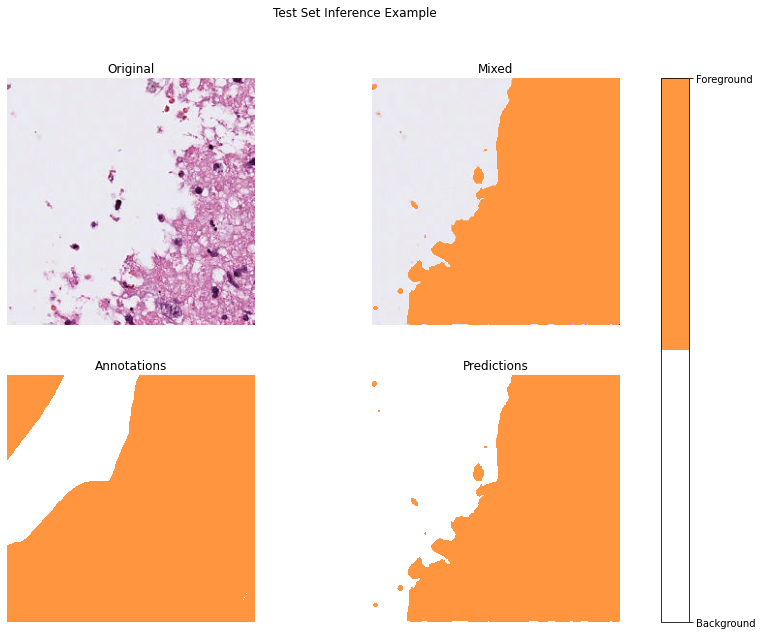

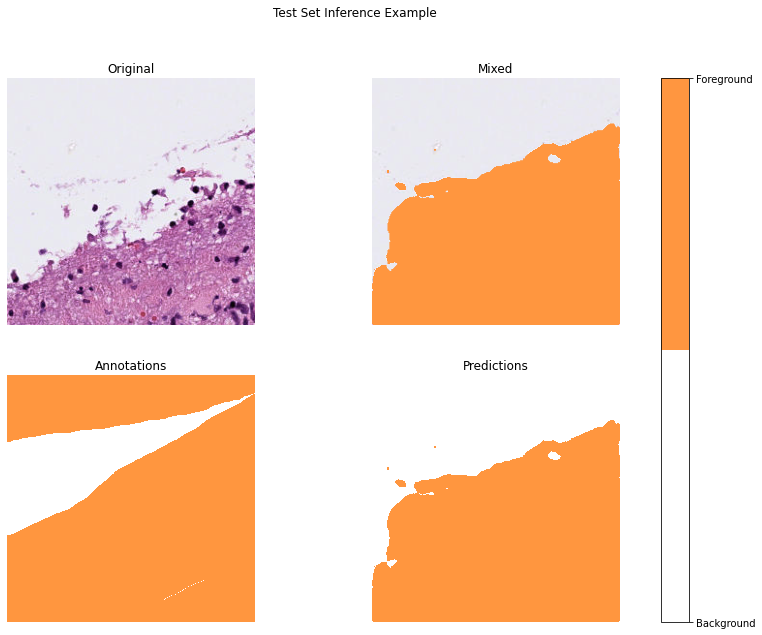

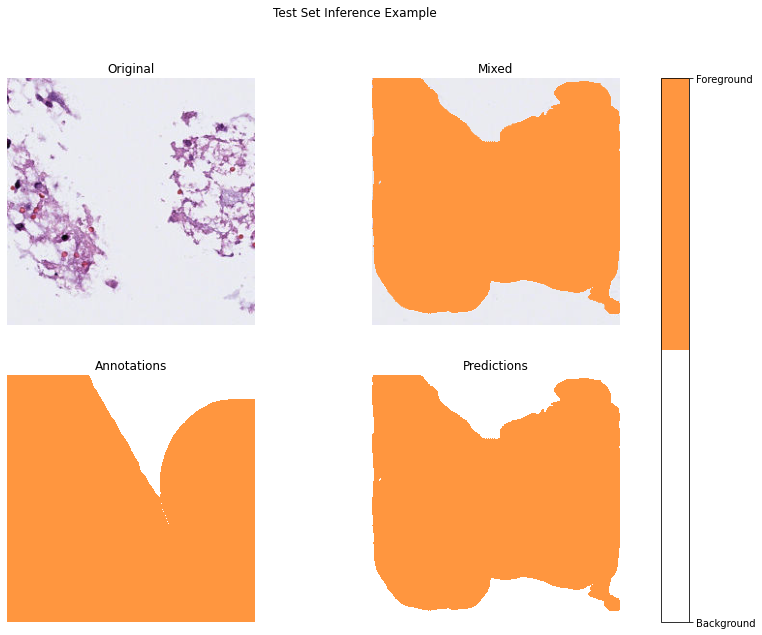

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os, random

# Edit here
n_examples_per_class = 5
out_dir = "plots_case1"
target_classes = [1]
# Edit ends

class_names = ["Background", "Foreground"]
for i in class_names[1:]:
    os.makedirs(os.path.join(out_dir, i), exist_ok  = True)
my_cmap = [(1., 1., 1.), (1., 0.59, 0.25)]
cmap = mpl.colors.ListedColormap(my_cmap)

with torch.no_grad():
    for label in target_classes:
        indexes = np.arange(0, len(test_set), 1)
        np.random.shuffle(indexes)
        image_box = []
        label_box = []
        sample_idx = 0
        while len(image_box) < n_examples_per_class and sample_idx < len(test_set):
            tissue_transposed, annotation = test_set[indexes[sample_idx]]
            annotation[annotation > 0] = 1
            ratio = (annotation == label).mean()
            if ratio > 0.1 and ratio < 0.9:
                image_box.append(tissue_transposed)
                label_box.append(annotation)
            sample_idx += 1
        preds = model(torch.tensor(image_box)).argmax(axis = 1).numpy()
        label_box = np.array(label_box)
        class_name = class_names[label]
        out_path = os.path.join(out_dir, class_name)
        for i in range(len(preds)):
            plot_name = f"{class_name}_{random.randint(0, 10000)}.png"
            plot_path = os.path.join(out_path, plot_name)
            fig, axes = plt.subplots(2, 2, figsize = (15, 10))
            fig.suptitle("Test Set Inference Example")
            for ax, title in zip(axes.ravel().tolist(), ["Original", "Mixed", "Annotations", "Predictions"]):
                ax.axis("off")
                ax.set_title(title)
            img = np.transpose(image_box[i], [1, 2, 0])
            img_min, img_max = img.min(axis = (0, 1)), img.max(axis = (0, 1))
            img_normalized = (img - img_min) / (img_max - img_min)
            axes[0][0].imshow(img_normalized)
            axes[0][1].imshow(img_normalized)
            axes[0][1].imshow(preds[i], alpha = (preds[i] > 0).astype(np.float32), cmap = cmap, vmin = 0, vmax = len(class_names) - 1)
            axes[1][0].imshow(label_box[i], cmap = cmap, vmin = 0, vmax = len(class_names) - 1)
            im = axes[1][1].imshow(preds[i], cmap = cmap, vmin = 0, vmax = len(class_names) - 1)
            
            cbar = fig.colorbar(im, ax=axes.ravel().tolist())
            cbar.ax.set_yticks(range(len(class_names)))
            cbar.ax.set_yticklabels(class_names)
            
            fig.savefig(plot_path, facecolor = "lightsteelblue")